# Notebook 04 — Monte Carlo VaR

Monte Carlo simulation estimates portfolio risk by generating a large number of possible future market scenarios.

The simulations are based on the portfolio's historical mean returns and covariance matrix. Each simulated scenario produces a portfolio return, allowing Value at Risk (VaR) and Expected Shortfall (ES) to be estimated from the simulated return distribution.

Monte Carlo methods are widely used because they can easily be extended to more complex portfolios and risk models.

**Simulation Size**
10,000 scenarios

## Outputs

- Monte Carlo VaR (95%, 99%)
- Monte Carlo Expected Shortfall
- Comparison with Historical and Parametric VaR


Monte Carlo VaR Results

Monte Carlo VaR (95%)
  VaR : 2.0190% ($20,190)
  ES  : 2.5329% ($25,329)

Monte Carlo VaR (99%)
  VaR : 2.7904% ($27,904)
  ES  : 3.2427% ($32,427)

VaR Model Comparison
Model                 95%       99%
Historical        1.8059%   3.4243%
Parametric        2.0046%   2.8562%
Monte Carlo       2.0190%   2.7904%


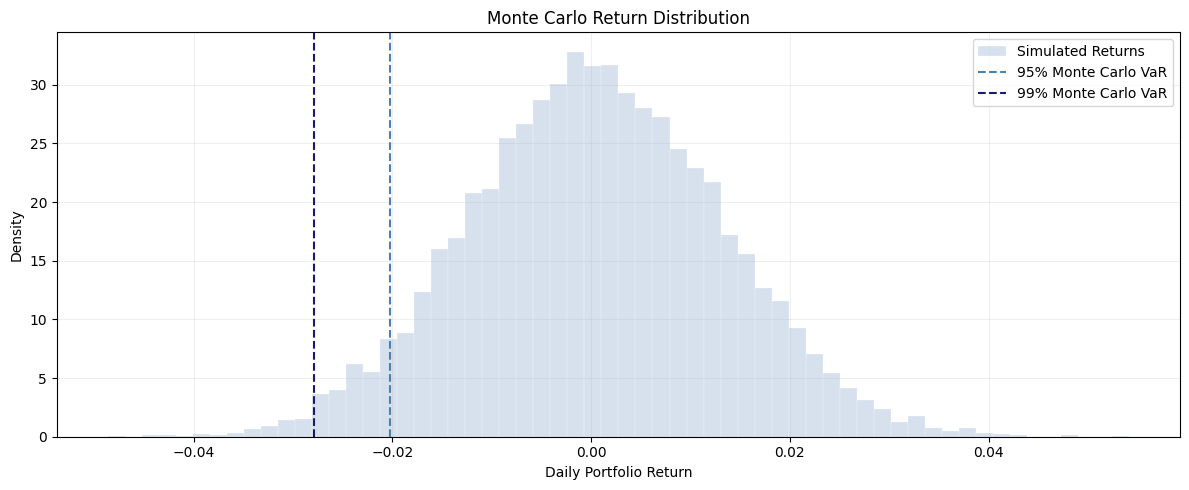

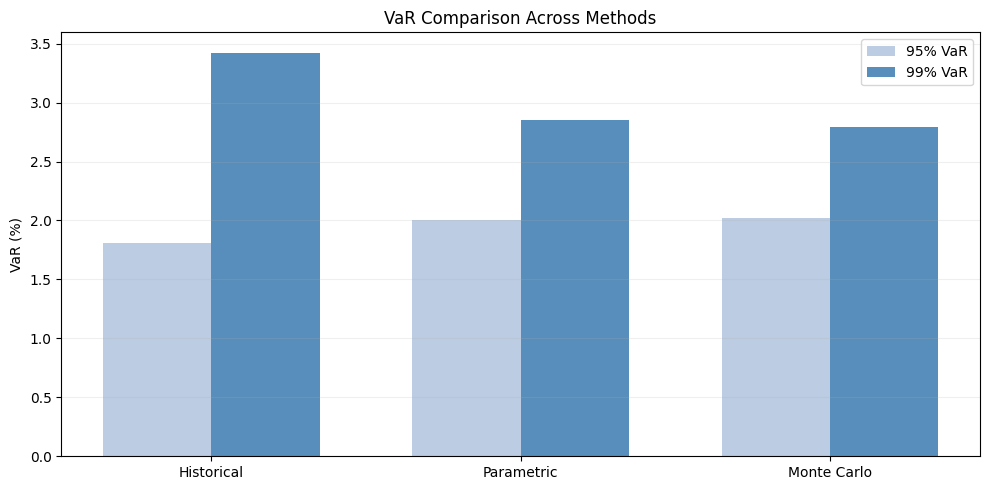

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

confidence_levels = [0.95, 0.99]

portfolio_value = 1_000_000

n_simulations = 10_000

np.random.seed(42)

# Load Data

log_returns = pd.read_csv( "../data/log_returns.csv",index_col=0,  parse_dates=True)

assert log_returns.isna().sum().sum() == 0

# Estimate Portfolio Distribution

mu = log_returns.mean().values

cov_matrix = log_returns.cov().values

# Monte Carlo Simulation

simulated_returns = np.random.multivariate_normal( mean=mu,cov=cov_matrix,size=n_simulations)

simulated_portfolio = simulated_returns @ weights

# Monte Carlo VaR

mc_results = {}

print("\nMonte Carlo VaR Results")

for cl in confidence_levels:

    tail = 1 - cl

    var_pct = -np.percentile(simulated_portfolio, tail * 100)

    es_pct = -simulated_portfolio[simulated_portfolio <= -var_pct].mean()

    var_dollar = var_pct * portfolio_value

    es_dollar = es_pct * portfolio_value

    mc_results[cl] = {
        "var_pct": var_pct,
        "es_pct": es_pct,
        "var_dollar": var_dollar,
        "es_dollar": es_dollar}

    print(f"\nMonte Carlo VaR ({cl*100:.0f}%)")
    print(f"  VaR : {var_pct*100:.4f}% (${var_dollar:,.0f})")
    print(f"  ES  : {es_pct*100:.4f}% (${es_dollar:,.0f})")

# Comparison with Historical and Parametric VaR

portfolio_returns = log_returns.dot(weights)

h_var_95 = -np.percentile(portfolio_returns, 5)
h_var_99 = -np.percentile(portfolio_returns, 1)

mu_p = weights @ mu
sigma_p = np.sqrt(weights @ cov_matrix @ weights)

p_var_95 = -(mu_p + norm.ppf(0.05) * sigma_p)
p_var_99 = -(mu_p + norm.ppf(0.01) * sigma_p)

mc_95 = mc_results[0.95]["var_pct"]
mc_99 = mc_results[0.99]["var_pct"]

print("\nVaR Model Comparison")
print(f"{'Model':<15}{'95%':>10}{'99%':>10}")
print(f"{'Historical':<15}{h_var_95*100:>9.4f}%{h_var_99*100:>9.4f}%")
print(f"{'Parametric':<15}{p_var_95*100:>9.4f}%{p_var_99*100:>9.4f}%")
print(f"{'Monte Carlo':<15}{mc_95*100:>9.4f}%{mc_99*100:>9.4f}%")

# Visualization 1

fig, ax = plt.subplots(figsize=(12,5))

ax.hist(
    simulated_portfolio,
    bins=60,
    density=True,
    color="lightsteelblue",
    alpha=0.50,
    edgecolor="white",
    linewidth=0.3,
    label="Simulated Returns")

ax.axvline(
    -mc_95,
    color="steelblue",
    linestyle="--",
    linewidth=1.5,
    label="95% Monte Carlo VaR")

ax.axvline(
    -mc_99,
    color="midnightblue",
    linestyle="--",
    linewidth=1.5,
    label="99% Monte Carlo VaR")

ax.set_title("Monte Carlo Return Distribution")
ax.set_xlabel("Daily Portfolio Return")
ax.set_ylabel("Density")

ax.legend()

ax.grid(alpha=0.2)

plt.tight_layout()

os.makedirs("../reports", exist_ok=True)

plt.savefig( "../reports/04_monte_carlo_distribution.png", dpi=150)

plt.show()

# Visualization 2

fig, ax = plt.subplots(figsize=(10,5))

labels = ["Historical", "Parametric", "Monte Carlo"]

var_95 = [
    h_var_95 * 100,
    p_var_95 * 100,
    mc_95 * 100]

var_99 = [
    h_var_99 * 100,
    p_var_99 * 100,
    mc_99 * 100]

x = np.arange(len(labels))

width = 0.35

ax.bar(
    x - width/2,
    var_95,
    width,
    color="lightsteelblue",
    alpha=0.85,
    label="95% VaR")

ax.bar(
    x + width/2,
    var_99,
    width,
    color="steelblue",
    alpha=0.90,
    label="99% VaR")

ax.set_title("VaR Comparison Across Methods")
ax.set_ylabel("VaR (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.legend()

ax.grid(alpha=0.2, axis="y")

plt.tight_layout()

plt.savefig( "../reports/04_var_comparison.png", dpi=150)

plt.show()